#Powered by [@CoinNoin](https://www.youtube.com/@CoinNoin)
[![Subscribe](https://img.shields.io/badge/YouTube-Subscribe%20@CoinNoin-red?style=for-the-badge&logo=youtube)](https://www.youtube.com/@CoinNoin)

In [1]:
#@title 1. Initialize Core Environment
#@markdown This prepares the ephemeral storage, installs ComfyUI, and configures the GGUF integration tools for Krea-2.

import os
import subprocess
from IPython.display import clear_output

LOCAL_WORKSPACE = "/content/ComfyUI"

print("🚀 [@CoinNoin] Initializing Core Architecture...")
if not os.path.exists(LOCAL_WORKSPACE):
    !git clone https://github.com/comfyanonymous/ComfyUI {LOCAL_WORKSPACE} &> /dev/null
    print("   ✓ Core Engine Cloned")
else:
    !cd {LOCAL_WORKSPACE} && git pull &> /dev/null
    print("   ✓ Core Engine Updated")

print("📦 [@CoinNoin] Installing Dependencies (This takes a moment)...")
!pip install -q uv
!cd {LOCAL_WORKSPACE} && uv pip install --system -q -r requirements.txt
!uv pip install --system -q gguf torchsde websocket-client

GGUF_NODE_DIR = os.path.join(LOCAL_WORKSPACE, "custom_nodes/ComfyUI-GGUF")
if not os.path.exists(GGUF_NODE_DIR):
    print("🧩 [@CoinNoin] Installing GGUF Processing Nodes...")
    !git clone https://github.com/city96/ComfyUI-GGUF {GGUF_NODE_DIR} &> /dev/null
    !uv pip install --system -q -r {GGUF_NODE_DIR}/requirements.txt

clear_output()
print("✅ [@CoinNoin] Environment Ready!")

✅ [@CoinNoin] Environment Ready!


In [2]:
#@title 2. High-Speed Asset Downloader & LoRA Setup
#@markdown The **Krea-2 Turbo Q5_K_M GGUF** and required base assets are fetched automatically. You can optionally download or upload a LoRA file.

# --- Optional LoRA Source ---
LORA_SOURCE = "Download from URL" #@param ["None (No LoRA)", "Download from URL", "Upload from Computer"]
LORA_URLS = "https://huggingface.co/bonticario/Krea-2-Realism-LoRA/resolve/main/krea2_realism_lora.safetensors" #@param {type:"string"}

import os
import subprocess
import urllib.parse
from google.colab import files

WORKSPACE = "/content/ComfyUI"

# Fixed UNet model (Locked to Krea-2 Turbo GGUF)
FIXED_UNET_URL = "https://huggingface.co/vantagewithai/Krea-2-Turbo-GGUF/resolve/main/krea2_turbo-Q5_K_M.gguf"
TEXT_ENCODER_URL = "https://huggingface.co/Comfy-Org/Qwen3-VL/resolve/main/text_encoders/qwen3vl_4b_fp8_scaled.safetensors"
VAE_URL = "https://huggingface.co/Comfy-Org/Qwen-Image_ComfyUI/resolve/main/split_files/vae/qwen_image_vae.safetensors"

DIRS = {
    "unet":  os.path.join(WORKSPACE, "models/unet"),
    "clip":  os.path.join(WORKSPACE, "models/clip"),
    "text_encoders": os.path.join(WORKSPACE, "models/text_encoders"),
    "vae":   os.path.join(WORKSPACE, "models/vae"),
    "loras": os.path.join(WORKSPACE, "models/loras"),
}

for p in DIRS.values():
    os.makedirs(p, exist_ok=True)

print("⚡ [@CoinNoin] Configuring Aria2c Accelerator...")
subprocess.run(['apt-get', '-y', 'install', '-qq', 'aria2'], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

def download_file(url, target_dir, filename=None):
    if not url.strip(): return
    if not filename:
        parsed_url = urllib.parse.urlparse(url)
        filename = os.path.basename(parsed_url.path)
    print(f"   📥 Fetching: {filename if filename else url[:40]}...")

    aria2_cmd = [
        "aria2c", "--console-log-level=error", "--summary-interval=10",
        "-c", "-x", "16", "-s", "16", "-k", "1M"
    ]
    if "civitai.com" in url or not filename:
        aria2_cmd.extend(["--content-disposition", url, "-d", target_dir])
    else:
        aria2_cmd.extend(["-o", filename, url, "-d", target_dir])

    subprocess.run(aria2_cmd, check=True)
    print(f"   ✅ Saved in {os.path.basename(target_dir)}")

# Download required base assets
download_file(FIXED_UNET_URL, DIRS["unet"])
download_file(TEXT_ENCODER_URL, DIRS["clip"])
download_file(VAE_URL, DIRS["vae"])

# Symlink CLIP for Krea compatibility
clip_src = os.path.join(DIRS["clip"], "qwen3vl_4b_fp8_scaled.safetensors")
clip_dst = os.path.join(DIRS["text_encoders"], "qwen3vl_4b_fp8_scaled.safetensors")
if os.path.exists(clip_src) and not os.path.exists(clip_dst):
    os.symlink(clip_src, clip_dst)

# Handle optional LoRA
ACTIVE_LORA_FILENAME = ""

if LORA_SOURCE == "Download from URL":
    if LORA_URLS.strip():
        parsed_name = os.path.basename(urllib.parse.urlparse(LORA_URLS.strip()).path)
        if not parsed_name.endswith(('.safetensors', '.pt', '.ckpt')):
            parsed_name = "downloaded_lora.safetensors"
        download_file(LORA_URLS.strip(), DIRS["loras"], filename=parsed_name)
        ACTIVE_LORA_FILENAME = parsed_name
    else:
        print("⚠️ No LoRA URL provided. Proceeding without LoRA.")
elif LORA_SOURCE == "Upload from Computer":
    print("\n📤 [@CoinNoin] Select your LoRA (.safetensors) file to upload:")
    uploaded = files.upload()
    if uploaded:
        for fname in uploaded.keys():
            dest = os.path.join(DIRS["loras"], fname)
            os.replace(fname, dest)
            ACTIVE_LORA_FILENAME = fname
            print(f"   ✅ LoRA uploaded: {fname}")
    else:
        print("⚠️ No file uploaded. Proceeding without LoRA.")
else:
    print("ℹ️ Running in Pure Base Model Mode (No LoRA).")

# List all available LoRAs in the directory
available_loras = [f for f in os.listdir(DIRS["loras"]) if f.endswith(('.safetensors', '.pt', '.ckpt'))]
print("\n📂 [@CoinNoin] Available LoRAs in storage:")
if available_loras:
    for idx, lora_name in enumerate(available_loras, 1):
        print(f"   {idx}. {lora_name}")
        if idx == 1:
          recent_lora = {lora_name}
else:
    print("   (None found - model will run without LoRA)")

print("\n✅ [@CoinNoin] All core assets secured!")

⚡ [@CoinNoin] Configuring Aria2c Accelerator...
   📥 Fetching: krea2_turbo-Q5_K_M.gguf...
   ✅ Saved in unet
   📥 Fetching: qwen3vl_4b_fp8_scaled.safetensors...
   ✅ Saved in clip
   📥 Fetching: qwen_image_vae.safetensors...
   ✅ Saved in vae
   📥 Fetching: krea2_realism_lora.safetensors...
   ✅ Saved in loras

📂 [@CoinNoin] Available LoRAs in storage:
   1. krea2_realism_lora.safetensors

✅ [@CoinNoin] All core assets secured!


https://www.youtube.com/watch?v=CnHwIZOWwzg

https://huggingface.co/models?sort=trending&search=krea+2+lora

🔌 [@CoinNoin] Checking ComfyUI Server Status...
   🚀 Starting ComfyUI Server in background...
   🟢 Server is now up and ready!
✨ [@CoinNoin] LoRA Applied: krea2_realism_lora.safetensors (Strength: 1)
➜ [@CoinNoin] Details | Res: 512x512 | Seed: 205004829551813 | Steps: 8
📥 Submitting workflow to API...
✨ Processing and Sampling (Check ComfyUI server logs if stuck)...
🖼️ Decoding Final Masterpiece...
✓ [@CoinNoin] Saved: KreaGenImage_00001_.png


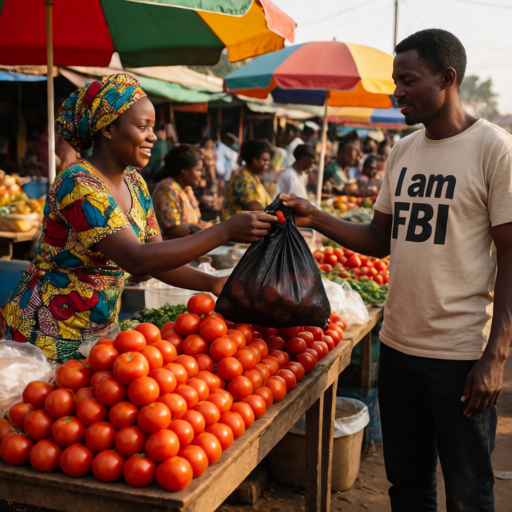


📦 Click the button below to download the generated image:



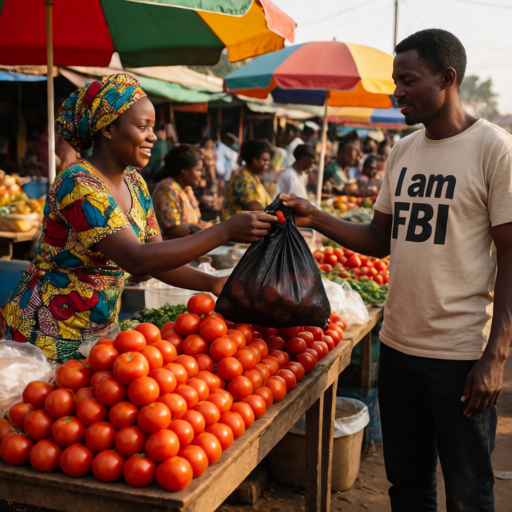

In [3]:
#@title 3. Image Generation
#@markdown Enter your prompt, tweak parameters, or select your LoRA from the dropdown.

# --- Model & LoRA Selection ---
DOWNLOAD_IMAGE_NAME = "KreaGenImage" #@param {type:"string"}
#@markdown *Guide: Choose **None** to run without LoRA, **auto** to use the most recent LoRA, or type/paste the exact filename from Step 2 (Available LoRAs).*
LORA_FILENAME = "auto" #@param ["None", "auto"] {allow-input: true}
LORA_Trigger_Words = "" #@param {type:"string"}
LORA_STRENGTH = 1 #@param {type:"slider", min:0.0, max:2.0, step:0.05}

# --- Generation Settings ---
POSITIVE_PROMPT = "A candid, realistic street photograph of a young Nigerian woman selling fresh, bright red tomatoes arranged in neat pyramids on a wooden table in a bustling Nigerian open-air market. She is wearing colorful Ankara print clothing and a headwrap, smiling warmly as she hands a black nylon bag of tomatoes to a customer. The customer is standing across the stall, wearing a casual t-shirt with the bold text \"I am FBI\" clearly printed across the chest. In the background, vibrant market stalls, umbrellas, shoppers, and warm natural sunlight create an authentic, lively atmosphere. Shot on a 35mm lens, sharp focus, rich natural colors." #@param {type:"string"}
NEGATIVE_PROMPT = "blurry, low quality, deformed, artifacts, bad anatomy" #@param {type:"string"}
BATCH_SIZE = 1 #@param {type:"slider", min:1, max:4, step:1}
WIDTH = 512 #@param {type:"slider", min:512, max:2048, step:64}
HEIGHT = 512 #@param {type:"slider", min:512, max:2048, step:64}
PROMPT = POSITIVE_PROMPT if LORA_FILENAME == "None" else LORA_Trigger_Words + ", " + POSITIVE_PROMPT

# --- Advanced Sampler Settings ---
STEPS = 8 #@param {type:"slider", min:1, max:20, step:1}
CFG = 1.0 #@param {type:"number"}
SAMPLER_NAME = "euler" #@param ["euler", "euler_ancestral", "heun", "dpm_2", "dpm_2_ancestral", "lms", "dpm_fast", "dpm_adaptive", "dpmpp_2s_ancestral", "dpmpp_sde", "dpmpp_sde_gpu", "dpmpp_2m", "dpmpp_2m_sde", "dpmpp_2m_sde_gpu", "dpmpp_3m_sde", "dpmpp_3m_sde_gpu", "ddpm", "lcm", "ddim", "uni_pc", "uni_pc_bh2", "res_multistep"] {allow-input: true}
SCHEDULER = "beta" #@param ["normal", "karras", "exponential", "sgm_uniform", "simple", "ddim_uniform", "beta"] {allow-input: true}
SEED = 0 #@param {type:"integer"}

# --- Direct Download (No ZIP) ---
AUTO_DOWNLOAD = False #@param {type:"boolean"}

import sys
import os
import json
import time
import random
import subprocess
import urllib.request
from google.colab import files
from IPython.display import display, Image as IPImage

WORKSPACE = "/content/ComfyUI"
os.chdir(WORKSPACE)

# Fixed GGUF Model Filename for Krea-2
UNET_FILENAME = "krea2_turbo-Q5_K_M.gguf"

# Auto-detect LoRA if set to 'auto'
if LORA_FILENAME.lower() == "auto":
    if 'ACTIVE_LORA_FILENAME' in globals() and ACTIVE_LORA_FILENAME:
      LORA_FILENAME = next(iter(recent_lora))
    else:
        lora_dir = os.path.join(WORKSPACE, "models/loras")
        available = [f for f in os.listdir(lora_dir) if f.endswith(('.safetensors', '.pt', '.ckpt'))] if os.path.exists(lora_dir) else []
        LORA_FILENAME = available[0] if available else "None"

if SEED == 0:
    SEED = random.randint(1, 1125899906842624)

print("🔌 [@CoinNoin] Checking ComfyUI Server Status...")
def start_server():
    req = urllib.request.Request("http://127.0.0.1:8188")
    try:
        urllib.request.urlopen(req)
        print("   🟢 Server is already running.")
    except:
        print("   🚀 Starting ComfyUI Server in background...")
        subprocess.Popen([sys.executable, "main.py"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        while True:
            try:
                urllib.request.urlopen(req)
                print("   🟢 Server is now up and ready!")
                break
            except:
                time.sleep(2)

start_server()

# Brand visibility prefix in filename
BRAND_PREFIX = DOWNLOAD_IMAGE_NAME

# Krea-2 Node Architecture
prompt_workflow = {
    "1": {"inputs": {"unet_name": UNET_FILENAME}, "class_type": "UnetLoaderGGUF"},
    "2": {"inputs": {"clip_name": "qwen3vl_4b_fp8_scaled.safetensors", "type": "krea2", "device": "default"}, "class_type": "CLIPLoader"},
    "3": {"inputs": {"vae_name": "qwen_image_vae.safetensors"}, "class_type": "VAELoader"},
    "4": {"inputs": {"text": PROMPT, "clip": ["2", 0]}, "class_type": "CLIPTextEncode"},
    "6": {"inputs": {"width": WIDTH, "height": HEIGHT, "batch_size": BATCH_SIZE}, "class_type": "EmptyLatentImage"},
    "8": {"inputs": {"samples": ["7", 0], "vae": ["3", 0]}, "class_type": "VAEDecode"},
    "9": {"inputs": {"filename_prefix": BRAND_PREFIX, "images": ["8", 0]}, "class_type": "SaveImage"}
}

# Apply Negative Prompt
if NEGATIVE_PROMPT.strip():
    prompt_workflow["5"] = {"inputs": {"text": NEGATIVE_PROMPT, "clip": ["2", 0]}, "class_type": "CLIPTextEncode"}
else:
    prompt_workflow["5"] = {"inputs": {"conditioning": ["4", 0]}, "class_type": "ConditioningZeroOut"}

# Attach LoRA only if specified and exists
model_output = ["1", 0]
if LORA_FILENAME.strip() and LORA_FILENAME.lower() != "none":
    lora_path = os.path.join(WORKSPACE, "models/loras", LORA_FILENAME)
    if os.path.exists(lora_path):
        prompt_workflow["10"] = {
            "inputs": {
                "lora_name": LORA_FILENAME,
                "strength_model": LORA_STRENGTH,
                "model": ["1", 0]
            },
            "class_type": "LoraLoaderModelOnly"
        }
        model_output = ["10", 0]
        print(f"✨ [@CoinNoin] LoRA Applied: {LORA_FILENAME} (Strength: {LORA_STRENGTH})")
    else:
        print(f"⚠️ LoRA '{LORA_FILENAME}' not found in models/loras. Running without LoRA.")
else:
    print("ℹ️ [@CoinNoin] Running generation without LoRA.")

prompt_workflow["7"] = {
    "inputs": {
        "seed": SEED,
        "steps": STEPS,
        "cfg": CFG,
        "sampler_name": SAMPLER_NAME,
        "scheduler": SCHEDULER,
        "denoise": 1.0,
        "model": model_output,
        "positive": ["4", 0],
        "negative": ["5", 0],
        "latent_image": ["6", 0]
    },
    "class_type": "KSampler"
}

p = {"prompt": prompt_workflow}
data = json.dumps(p).encode('utf-8')
req = urllib.request.Request("http://127.0.0.1:8188/prompt", data=data)

print(f"\033[94m➜ [@CoinNoin] Details | Res: {WIDTH}x{HEIGHT} | Seed: {SEED} | Steps: {STEPS}\033[0m")
print("📥 Submitting workflow to API...")
try:
    response = urllib.request.urlopen(req)
    prompt_id = json.loads(response.read())['prompt_id']
except Exception as e:
    print(f"❌ API Error: {e}")
    raise

print("✨ Processing and Sampling (Check ComfyUI server logs if stuck)...")
while True:
    try:
        history_req = urllib.request.Request(f"http://127.0.0.1:8188/history/{prompt_id}")
        history_res = urllib.request.urlopen(history_req)
        history_data = json.loads(history_res.read())
        if prompt_id in history_data:
            outputs = history_data[prompt_id]['outputs']
            break
    except:
        pass
    time.sleep(1)

print("🖼️ Decoding Final Masterpiece...")
generated_images = []
for node_id, node_output in outputs.items():
    if 'images' in node_output:
        for image in node_output['images']:
            filename = image['filename']
            img_path = os.path.join(WORKSPACE, "output", filename)
            generated_images.append(img_path)
            print(f"\033[92m✓ [@CoinNoin] Saved: {filename}\033[0m")
            display(IPImage(filename=img_path))

# Direct download trigger
if AUTO_DOWNLOAD and generated_images:
    print("\n📥 [@CoinNoin] Download Started...")
    for img_file in generated_images:
        files.download(img_file)

# ====== ⬇️ DOWNLOAD BUTTON (downloads ONLY when clicked) ======
from IPython.display import HTML
import base64 as _b64

if generated_images:
    print("\n📦 Click the button below to download the generated image:")
    _mime_map = {
        "png":  "image/png",
        "jpg":  "image/jpeg",
        "jpeg": "image/jpeg",
        "webp": "image/webp",
        "gif":  "image/gif",
    }
    for output_path in generated_images:
        output_filename = os.path.basename(output_path)
        ext = os.path.splitext(output_filename)[1].lower().lstrip(".")
        mime_type = _mime_map.get(ext, "image/png")
        with open(output_path, "rb") as _f:
            img_b64 = _b64.b64encode(_f.read()).decode()

        download_button = HTML(f'''
<a href="data:{mime_type};base64,{img_b64}"
   download="{output_filename}"
   style="
     display: inline-block;
     padding: 10px 20px;
     background-color: #4CAF50;
     color: white;
     text-decoration: none;
     border-radius: 6px;
     font-family: Arial, sans-serif;
     font-size: 14px;
     font-weight: bold;
     cursor: pointer;
   ">
   ⬇️ Download {output_filename}
</a>
''')
        display(download_button)
else:
    print("\n⚠️ No image was generated to download.")